## Ensemble learning

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

In [3]:
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = make_moons(n_samples=1000, noise=0.30, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=42,test_size=0.2)

voting_clf = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(random_state=42)),
        ('rf', RandomForestClassifier(random_state=42)),
        ('svc', SVC(random_state=42))
    ]
)

voting_clf.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('rf', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001


In [4]:
for name, clf in voting_clf.named_estimators_.items():
    print(name, "=", clf.score(X_test, y_test))

lr = 0.82
rf = 0.905
svc = 0.915


In [5]:
print(voting_clf.predict(X_test[:1]))
print([clf.predict(X_test[:1]) for clf in voting_clf.estimators_])
print(voting_clf.score(X_test, y_test))

[1]
[array([1]), array([1]), array([1])]
0.905


In [6]:
VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(random_state=42)),
        ("rf", RandomForestClassifier(random_state=42)),
        ("svc", SVC(random_state=42))
    ],
    voting="soft",
    weights=[2, 1, 1]
)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('rf', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.","[2, 1, ...]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001


Bagging

In [7]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=100,
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)

bag_clf.fit(X_train, y_train)

y_pred = bag_clf.predict(X_test)
print(bag_clf.score(X_test, y_test))

0.91


Pasting

In [8]:
paste_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=100,
    bootstrap=False,
    n_jobs=-1,
    random_state=42
)

paste_clf.fit(X_train, y_train)

print(paste_clf.score(X_test, y_test))

0.905


Feature importance

In [9]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
rnd_clf = RandomForestClassifier(n_estimators=500, random_state=42)
rnd_clf.fit(iris.data, iris.target)
for score, name in zip(rnd_clf.feature_importances_, iris.data.columns):
    print(round(score, 2), name)

0.11 sepal length (cm)
0.02 sepal width (cm)
0.44 petal length (cm)
0.42 petal width (cm)


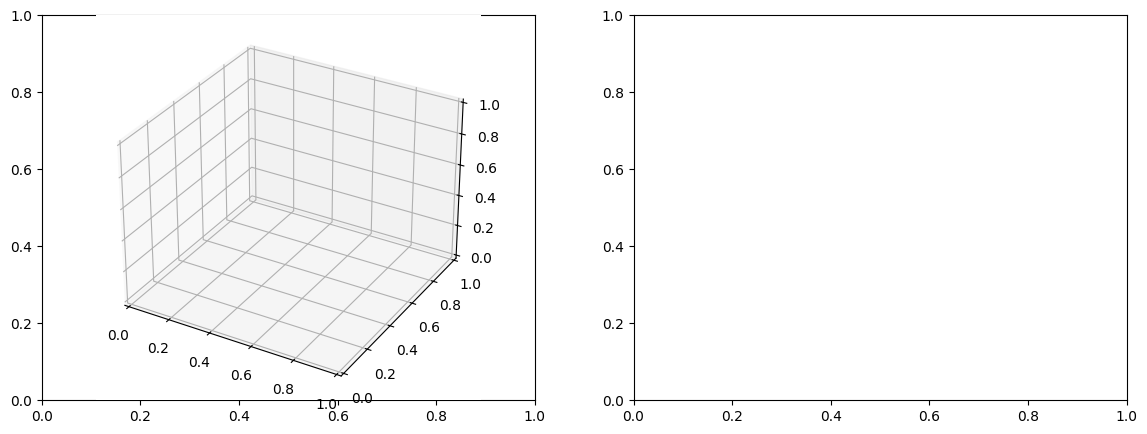

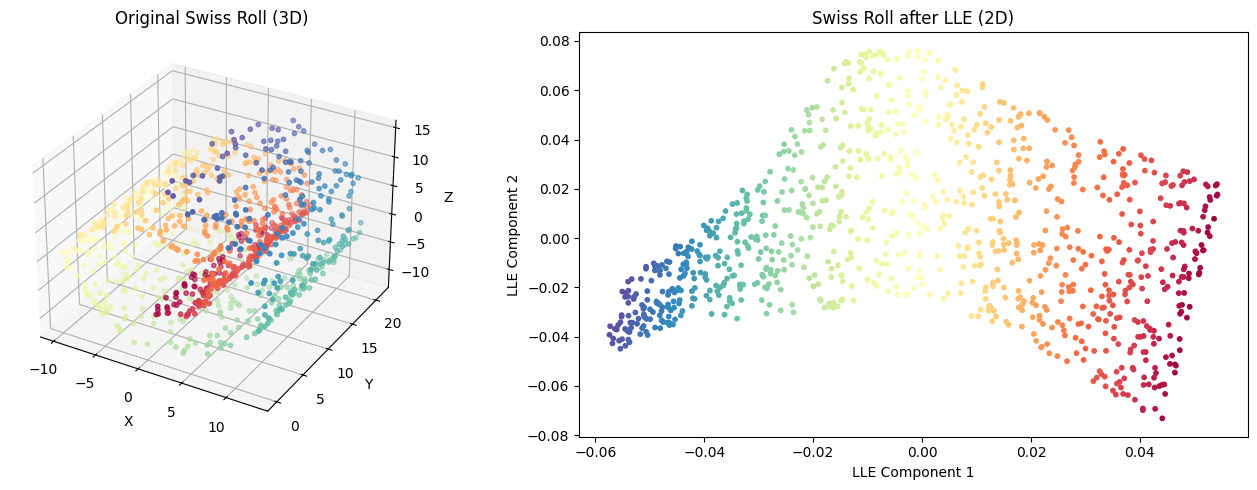

<Figure size 640x480 with 0 Axes>

In [13]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original Swiss Roll (3D)
axes[0] = fig.add_subplot(1, 2, 1, projection='3d')
X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)
X_unrolled = LocallyLinearEmbedding(
    n_neighbors=12,
    n_components=2,
    random_state=42
).fit_transform(X_swiss)

fig = plt.figure(figsize=(14, 5))

# Original Swiss Roll (3D)
ax0 = fig.add_subplot(1, 2, 1, projection="3d")
ax0.scatter(
    X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2],
    c=t, cmap="Spectral", s=10
)
ax0.set_title("Original Swiss Roll (3D)")
ax0.set_xlabel("X")
ax0.set_ylabel("Y")
ax0.set_zlabel("Z")

# LLE result (2D)
ax1 = fig.add_subplot(1, 2, 2)
ax1.scatter(
    X_unrolled[:, 0], X_unrolled[:, 1],
    c=t, cmap="Spectral", s=10
)
ax1.set_title("Swiss Roll after LLE (2D)")
ax1.set_xlabel("LLE Component 1")
ax1.set_ylabel("LLE Component 2")

plt.tight_layout()
plt.show()
axes[0].set_title("Original Swiss Roll (3D)")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_zlabel("Z")

# LLE-এর পরে (2D)
axes[1] = fig.add_subplot(1, 2, 2)
axes[1].scatter(
    X_unrolled[:, 0],
    X_unrolled[:, 1],
    c=t,
    cmap='Spectral',
    s=10
)
axes[1].set_title("Swiss Roll after LLE (2D)")
axes[1].set_xlabel("LLE Component 1")
axes[1].set_ylabel("LLE Component 2")

plt.tight_layout()
plt.show()

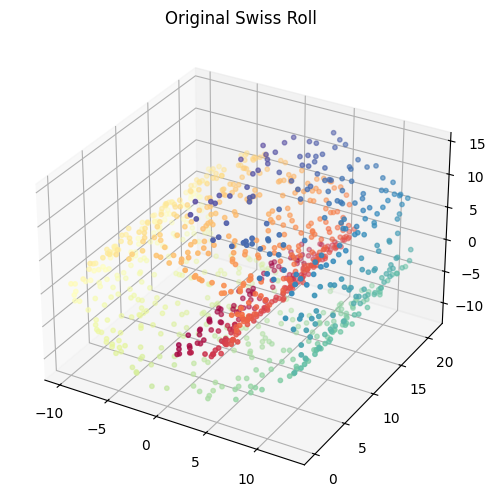

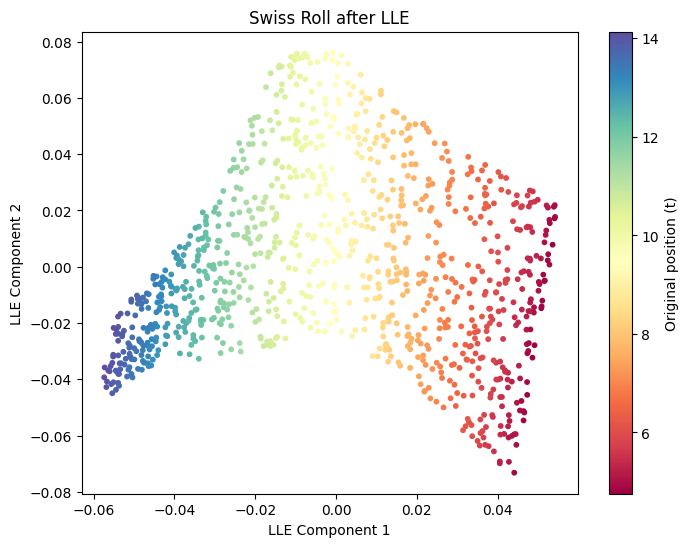

In [14]:
# Original 3D Swiss Roll
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X_swiss[:, 0],
    X_swiss[:, 1],
    X_swiss[:, 2],
    c=t,
    cmap='Spectral',
    s=10
)

ax.set_title("Original Swiss Roll")
plt.show()


# LLE Transformed 2D Data
plt.figure(figsize=(8, 6))

plt.scatter(
    X_unrolled[:, 0],
    X_unrolled[:, 1],
    c=t,
    cmap='Spectral',
    s=10
)

plt.title("Swiss Roll after LLE")
plt.xlabel("LLE Component 1")
plt.ylabel("LLE Component 2")
plt.colorbar(label="Original position (t)")
plt.show()

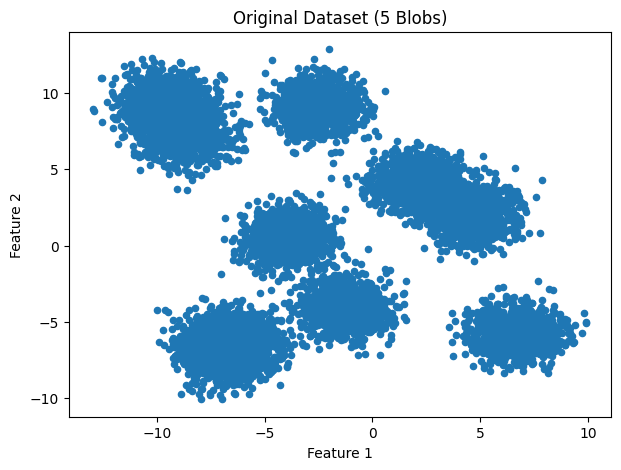

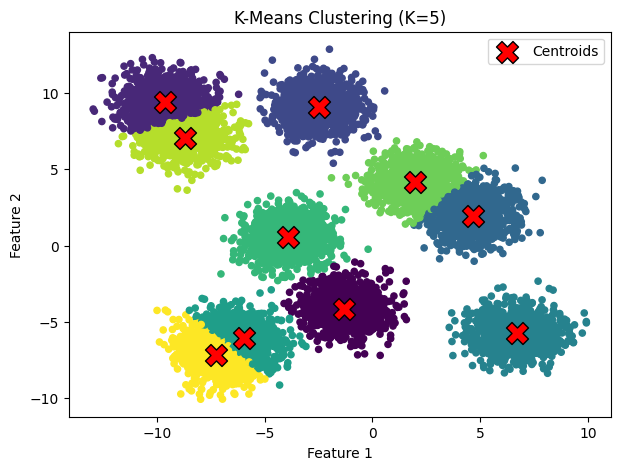

In [15]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate blobs
X, y = make_blobs(
    n_samples=10000,
    centers=10,
    n_features=2,
    cluster_std=1.0,
    random_state=42
)

# 2. Plot original data
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=20)
plt.title("Original Dataset (5 Blobs)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 3. Apply K-Means
kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

y_pred = kmeans.fit_predict(X)

# 4. Plot clustered data
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y_pred,
    cmap="viridis",
    s=20
)

# Plot centroids
centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Centroids"
)

plt.title("K-Means Clustering (K=5)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [ ]:
kmeans.cluster_centers_

array([[-1.32173515, -4.1541235 ],
       [-9.64120482,  9.3809393 ],
       [-2.47366913,  9.06523121],
       [ 4.65352473,  1.96488841],
       [ 6.69449144, -5.72198914],
       [-5.95467276, -6.0252552 ],
       [-3.91548329,  0.55263816],
       [ 1.96308321,  4.20175269],
       [-8.68768515,  7.06567224],
       [-7.26732821, -7.17919878]])

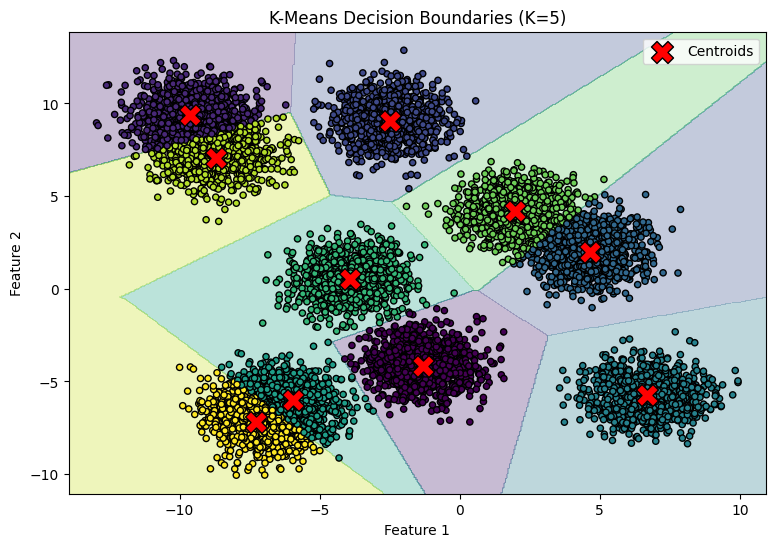

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a mesh grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# 2. Predict cluster for every point in the grid
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 3. Plot decision regions
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

# Plot original data points
plt.scatter(
    X[:, 0], X[:, 1],
    c=kmeans.labels_,
    cmap="viridis",
    s=20,
    edgecolors="k"
)

# Plot centroids
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Centroids"
)

plt.title("K-Means Decision Boundaries (K=5)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

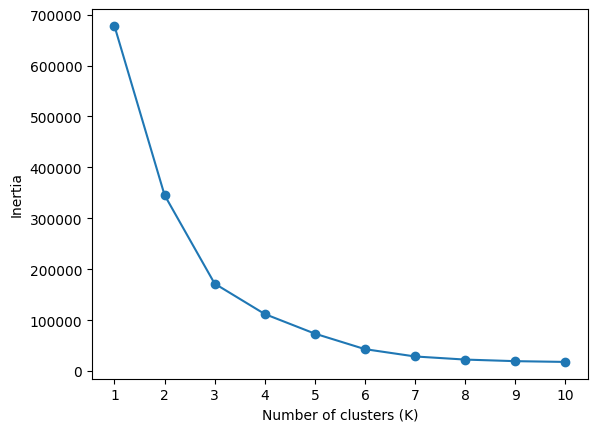

In [16]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.show()

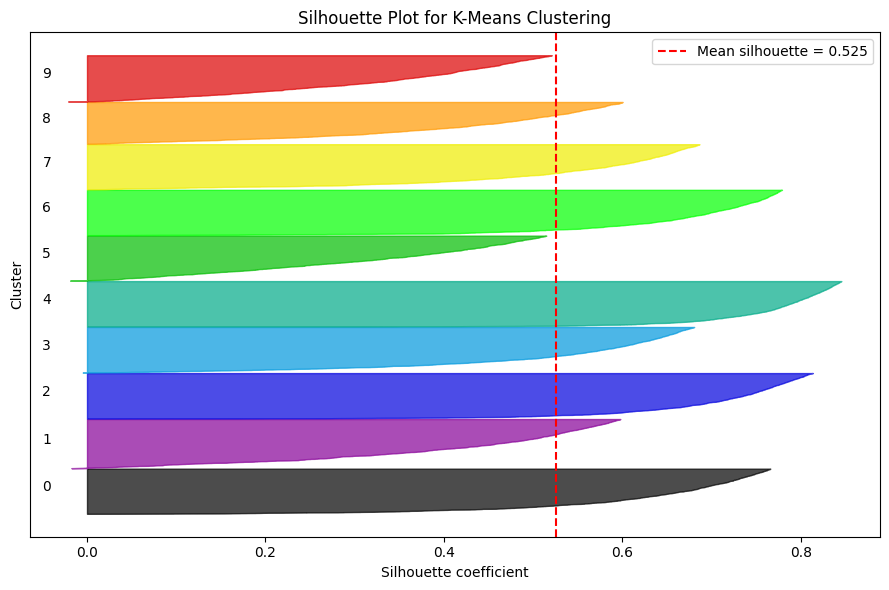

Average silhouette coefficient: 0.525


In [17]:
from sklearn.metrics import silhouette_samples, silhouette_score

cluster_labels = kmeans.labels_
sample_silhouette_values = silhouette_samples(X, cluster_labels)
average_silhouette = silhouette_score(X, cluster_labels)

fig, ax_sil = plt.subplots(figsize=(9, 6))
y_lower = 10

for cluster_id in np.unique(cluster_labels):
    cluster_values = sample_silhouette_values[cluster_labels == cluster_id]
    cluster_values.sort()

    size = len(cluster_values)
    y_upper = y_lower + size

    color = plt.cm.nipy_spectral(cluster_id / len(np.unique(cluster_labels)))
    ax_sil.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.7
    )
    ax_sil.text(-0.05, y_lower + size / 2, str(cluster_id))
    y_lower = y_upper + 10

ax_sil.axvline(
    average_silhouette,
    color="red",
    linestyle="--",
    label=f"Mean silhouette = {average_silhouette:.3f}"
)
ax_sil.set_title("Silhouette Plot for K-Means Clustering")
ax_sil.set_xlabel("Silhouette coefficient")
ax_sil.set_ylabel("Cluster")
ax_sil.set_yticks([])
ax_sil.legend()
plt.tight_layout()
plt.show()

print(f"Average silhouette coefficient: {average_silhouette:.3f}")